In [ ]:
import pandas as pd
import os

print("Files available in Colab:")
print(os.listdir("/content"))

Files available in Colab:
['.config', 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'network_intrusion_detector.pkl', 'feature_names.pkl', 'sample_data']


In [ ]:
from IPython.display import display as show_table

file_path = "/content/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

df = pd.read_csv(file_path, nrows=10000)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
show_table(df.head())

Dataset shape: (10000, 79)

Column names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH F

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
# 1. Remove extra spaces from column names
df.columns = df.columns.str.strip()

# 2. Check the dataset size
print("Dataset shape:", df.shape)

# 3. Check the types of traffic labels
print("\nTraffic labels:")
print(df["Label"].value_counts())

# 4. Check for missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# 5. Check for infinite values
print(
    "Total infinite values:",
    np.isinf(df.select_dtypes(include=np.number)).sum().sum()
)

# 6. Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (10000, 79)

Traffic labels:
Label
BENIGN    10000
Name: count, dtype: int64

Total missing values: 1
Total infinite values: 13

Duplicate rows: 73


In [ ]:
# Load the complete CSV
df = pd.read_csv(file_path, low_memory=False)

# Clean column names
df.columns = df.columns.str.strip()

# Display the full dataset size
print("Full dataset shape:", df.shape)

# Count every traffic label
print("\nTraffic label distribution:")
print(df["Label"].value_counts())

# Show the percentage of each label
print("\nTraffic label percentages:")
print(
    (df["Label"].value_counts(normalize=True) * 100).round(2)
)

Full dataset shape: (225745, 79)

Traffic label distribution:
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

Traffic label percentages:
Label
DDoS      56.71
BENIGN    43.29
Name: proportion, dtype: float64


In [ ]:
# Check missing values
print("Total missing values:",
      df.isnull().sum().sum())

# Check infinite numeric values
numeric_df = df.select_dtypes(include=np.number)

print("Total infinite values:",
      np.isinf(numeric_df).sum().sum())

# Check duplicate rows
print("Duplicate rows:",
      df.duplicated().sum())

# Check the data types
print("\nData types:")
print(df.dtypes.value_counts())

# Check the target labels again
print("\nLabels:")
print(df["Label"].value_counts())

Total missing values: 4
Total infinite values: 64
Duplicate rows: 2633

Data types:
int64      54
float64    24
object      1
Name: count, dtype: int64

Labels:
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [ ]:
# Step 1: Find columns containing missing values
print("Columns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Step 2: Find columns containing infinite values
numeric_df = df.select_dtypes(include=np.number)
infinite_counts = np.isinf(numeric_df).sum()

print("\nColumns with infinite values:")
print(infinite_counts[infinite_counts > 0])

# Step 3: Count rows affected by either problem
df_check = df.replace([np.inf, -np.inf], np.nan)

print("\nRows containing missing or infinite values:",
      df_check.isnull().any(axis=1).sum())

Columns with missing values:
Flow Bytes/s    4
dtype: int64

Columns with infinite values:
Flow Bytes/s      30
Flow Packets/s    34
dtype: int64

Rows containing missing or infinite values: 34


In [ ]:
# Make a copy of the original dataset
df_clean = df.copy()

# Replace positive and negative infinity with missing values
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove rows containing missing values
df_clean.dropna(inplace=True)

# Remove exact duplicate rows
df_clean.drop_duplicates(inplace=True)

# Reset the row index
df_clean.reset_index(drop=True, inplace=True)

# Check the results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:",
      df_clean.isnull().sum().sum())

print("Remaining infinite values:",
      np.isinf(
          df_clean.select_dtypes(include=np.number)
      ).sum().sum())

print("Remaining duplicate rows:", df_clean.duplicated().sum())

print("\nLabels after cleaning:")
print(df_clean["Label"].value_counts())

Original dataset shape: (225745, 79)
Cleaned dataset shape: (223082, 79)

Remaining missing values: 0
Remaining infinite values: 0
Remaining duplicate rows: 0

Labels after cleaning:
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [ ]:
# X = input features
X = df_clean.drop(columns=["Label"])

# y = target labels
y = df_clean["Label"]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

print("\nFeature column examples:")
print(X.columns[:10].tolist())

print("\nTarget label examples:")
print(y.head().tolist())

Features shape: (223082, 78)
Labels shape: (223082,)

Feature column examples:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']

Target label examples:
['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training features: (178465, 78)
Testing features: (44617, 78)

Training label distribution:
Label
DDoS      102411
BENIGN     76054
Name: count, dtype: int64

Testing label distribution:
Label
DDoS      25603
BENIGN    19014
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model using the training data
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
from IPython.display import display as show_table

# Predict labels for unseen test records
y_pred = model.predict(X_test)

# Display a few predictions beside the actual labels
results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

show_table(results)

,Actual,Predicted
0,BENIGN,BENIGN
1,DDoS,DDoS
2,BENIGN,BENIGN
3,DDoS,DDoS
4,DDoS,DDoS
5,DDoS,DDoS
6,DDoS,DDoS
7,BENIGN,BENIGN
8,BENIGN,BENIGN
9,BENIGN,BENIGN


Accuracy: 0.9999

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617



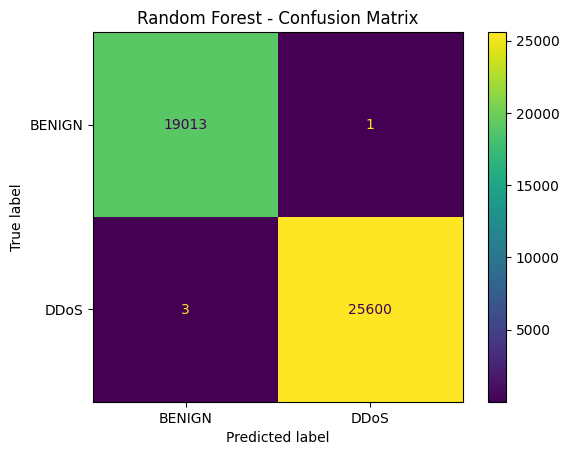

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Overall accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Detailed metrics for each class
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Visualize the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["BENIGN", "DDoS"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "DDoS"]
)

display.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Compare training and testing accuracy
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.6f}")
print(f"Testing accuracy:  {test_accuracy:.6f}")

# Display exact class-level metrics
print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    digits=6
))

# Display the numeric confusion matrix
print("\nConfusion matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["BENIGN", "DDoS"]
))

Training accuracy: 1.000000
Testing accuracy:  0.999910

Detailed classification report:
              precision    recall  f1-score   support

      BENIGN   0.999842  0.999947  0.999895     19014
        DDoS   0.999961  0.999883  0.999922     25603

    accuracy                       0.999910     44617
   macro avg   0.999902  0.999915  0.999908     44617
weighted avg   0.999910  0.999910  0.999910     44617


Confusion matrix:
[[19013     1]
 [    3 25600]]


In [ ]:
from IPython.display import display as show_table

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 15 important features:")
show_table(importance.head(15).to_frame("Importance"))

Top 15 important features:


,Importance
Fwd Packet Length Max,0.088353
Fwd Packet Length Mean,0.082392
Init_Win_bytes_forward,0.081292
Bwd Packet Length Min,0.070585
Avg Fwd Segment Size,0.062709
Subflow Fwd Bytes,0.049364
Subflow Fwd Packets,0.046797
act_data_pkt_fwd,0.044248
Total Length of Fwd Packets,0.039068
Destination Port,0.038713


In [ ]:
import joblib

# Save the trained Random Forest model
joblib.dump(model, "network_intrusion_detector.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
# Save the feature names in their original order
joblib.dump(
    X_train.columns.tolist(),
    "feature_names.pkl"
)

print("Feature names saved successfully!")

Feature names saved successfully!


In [ ]:
# Select one record from the test set
sample = X_test.iloc[[0]]

# Predict its label
prediction = model.predict(sample)[0]

# Retrieve the actual label
actual = y_test.iloc[0]

print("Predicted class:", prediction)
print("Actual class:", actual)
print("Prediction correct:", prediction == actual)

Predicted class: BENIGN
Actual class: BENIGN
Prediction correct: True


In [ ]:
from IPython.display import display as show_table

# Select 10 records from the test dataset
demo_X = X_test.iloc[:10]
demo_y = y_test.iloc[:10]

# Generate predictions
demo_predictions = model.predict(demo_X)

# Create a results table
demo_results = pd.DataFrame({
    "Actual Traffic": demo_y.values,
    "Predicted Traffic": demo_predictions,
    "Correct": demo_y.values == demo_predictions
})

show_table(demo_results)

,Actual Traffic,Predicted Traffic,Correct
0,BENIGN,BENIGN,True
1,DDoS,DDoS,True
2,BENIGN,BENIGN,True
3,DDoS,DDoS,True
4,DDoS,DDoS,True
5,DDoS,DDoS,True
6,DDoS,DDoS,True
7,BENIGN,BENIGN,True
8,BENIGN,BENIGN,True
9,BENIGN,BENIGN,True


In [ ]:
import joblib

# Load the saved model and feature names
loaded_model = joblib.load("network_intrusion_detector.pkl")
loaded_features = joblib.load("feature_names.pkl")

# Predict with the reloaded model
loaded_prediction = loaded_model.predict(X_test.iloc[[0]])[0]

print("Saved model loaded successfully!")
print("Number of saved features:", len(loaded_features))
print("Prediction from reloaded model:", loaded_prediction)

Saved model loaded successfully!
Number of saved features: 78
Prediction from reloaded model: BENIGN


In [ ]:
import joblib
import pandas as pd
from IPython.display import display as show_table

# Load the saved model and feature names
loaded_model = joblib.load("network_intrusion_detector.pkl")
loaded_features = joblib.load("feature_names.pkl")

# Select 10 unseen test records
demo_X = X_test[loaded_features].iloc[:10]
actual_labels = y_test.iloc[:10].values

# Predict network traffic classes
predicted_labels = loaded_model.predict(demo_X)

# Display results
demo_results = pd.DataFrame({
    "Actual Traffic": actual_labels,
    "Predicted Traffic": predicted_labels,
    "Result": [
        "Correct" if actual == predicted else "Incorrect"
        for actual, predicted in zip(actual_labels, predicted_labels)
    ]
})

show_table(demo_results)

print("\nDemo Summary")
print("Total records:", len(demo_results))
print("Correct predictions:", sum(actual_labels == predicted_labels))
print("Demo accuracy:",
      f"{(actual_labels == predicted_labels).mean() * 100:.2f}%")

,Actual Traffic,Predicted Traffic,Result
0,BENIGN,BENIGN,Correct
1,DDoS,DDoS,Correct
2,BENIGN,BENIGN,Correct
3,DDoS,DDoS,Correct
4,DDoS,DDoS,Correct
5,DDoS,DDoS,Correct
6,DDoS,DDoS,Correct
7,BENIGN,BENIGN,Correct
8,BENIGN,BENIGN,Correct
9,BENIGN,BENIGN,Correct



Demo Summary
Total records: 10
Correct predictions: 10
Demo accuracy: 100.00%
